# 9-2. auto_arima의 p,q 선택 (AIC vs AICc)

**전체 계획** (auto_arima만 사용, GARCH/SV는 나중에)

1. d 고정 (`9-1`: d=1)
2. **auto_arima로 p,q 선택 (AIC vs AICc)** (이 노트북)
3. 원 스케일: 리샘플링 vs 자체 7분위 비교
4. 로그 스케일: 리샘플링 vs 자체 7분위 비교

**공통 조건**: CRPS는 모델 자체 구간의 7분위(10·20·30·50·70·80·90%)로 계산한다.

**설계**: d=1만 고정하고 나머지는 모두 `auto_arima` 기본값에 맡긴다. 바꿔 비교하는 것은 **AIC vs AICc**뿐이다. 각 origin에서 그 시점까지의 데이터로만 차수를 고르므로 평가 데이터로 고르는 선택 편향이 없다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D = 1

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
var_std = vals.std()
scored_origins = list(range(MIN_TRAIN, len(vals) - H + 1))[INITIAL_CALIB:]
FIRST = scored_origins[0]


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def period(o):
    return {"훈련 기간": f"{quarters[0]}~{quarters[o - 1]}", "예측 기간": f"{quarters[o]}~{quarters[o + H - 1]}"}


LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def quantiles7(m):
    # 모델 자체의 구간: alpha 0.2/0.4/0.6 -> 10~90, 20~80, 30~70%, 50%는 점예측
    fc = m.predict(n_periods=H)
    q = {0.5: fc}
    for alpha in (0.2, 0.4, 0.6):
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=alpha)
        q[round(alpha / 2, 1)], q[round(1 - alpha / 2, 1)] = conf[:, 0], conf[:, 1]
    return fc, np.array([q[t] for t in LEVELS])  # (7, H)


print(f"전체 {len(vals)}분기 ({quarters[0]}~{quarters[-1]}), 채점 origin {len(scored_origins)}개, d={D} 고정")
print("첫 origin:", label(FIRST))
print("마지막 origin:", label(scored_origins[-1]))


전체 60분기 (2011Q1~2025Q4), 채점 origin 22개, d=1 고정
첫 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)


## 1. 설정 -- auto_arima의 기본 동작

```python
pm.auto_arima(train, d=1, seasonal=False, information_criterion="aic" 또는 "aicc")
```

| 항목 | 값 | 의미 |
|---|---|---|
| `d` | 1 (고정) | 9-1에서 정함 |
| `max_p`, `max_q` | 5, 5 | p,q 탐색 범위 |
| `stepwise` | True | 작은 모델에서 시작해 좋아지는 방향으로만 탐색 |
| `with_intercept` | `"auto"` | 절편(드리프트) 포함 여부도 정보기준으로 탐색 |

**AIC vs AICc**: `AICc = AIC + 2k(k+1)/(n-k-1)`(k 모수 수, n 관측 수). 표본이 작을수록 복잡한 모델에 큰 벌점을 준다.

In [2]:
for ic in ["aic", "aicc"]:
    m = pm.auto_arima(vals[:FIRST], d=D, seasonal=False, information_criterion=ic, suppress_warnings=True, error_action="ignore")
    params = dict(zip(m.arima_res_.model.param_names, np.round(m.arima_res_.params, 3)))
    print(f"{ic.upper():4s} {label(FIRST)}")
    print(f"     선택된 (p,d,q)={m.order}, 절편 포함={m.with_intercept}, 계수={params}")


AIC  origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
     선택된 (p,d,q)=(1, 1, 0), 절편 포함=True, 계수={'intercept': np.float64(12.424), 'ar.L1': np.float64(0.482), 'sigma2': np.float64(2422.102)}


AICC origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
     선택된 (p,d,q)=(1, 1, 0), 절편 포함=False, 계수={'ar.L1': np.float64(0.546), 'sigma2': np.float64(2564.692)}


## 2. origin별 선택된 (p,d,q)와 성능

22개 origin마다 AIC와 AICc로 `auto_arima`를 돌려 선택된 차수, 절편, 성능을 기록한다. 지표는 **CRPS(7분위)**(모델 구간의 분위수 7개, `2 x mean(pinball) / var_std`), **커버리지**(90% 구간 적중률), **MSE**다.

In [3]:
def run_ic(ic):
    out = []
    for o in scored_origins:
        train, actual = vals[:o], vals[o:o + H]
        m = pm.auto_arima(train, d=D, seasonal=False, information_criterion=ic, suppress_warnings=True, error_action="ignore")
        fc, q7 = quantiles7(m)
        crps7 = 2 * np.mean([pinball(q7[k], actual, LEVELS[k]) for k in range(7)], axis=0) / var_std
        _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        sig = np.maximum((conf[:, 1] - conf[:, 0]) / (2 * Z), 1e-6)
        p, _, q = m.order
        out.append({"origin": o, **period(o), "order": m.order, "p": p, "q": q, "절편": m.with_intercept,
                    "커버리지": 100 * np.mean((actual >= conf[:, 0]) & (actual <= conf[:, 1])),
                    "MSE": np.mean(((actual - fc) / var_std) ** 2),
                    "CRPS(7분위)": crps7.mean()})
    return pd.DataFrame(out).set_index("origin")


CACHE = "../cache/cache_92_ic_q7_df.pkl"
if os.path.exists(CACHE):
    res = pd.read_pickle(CACHE)
else:
    res = pd.concat({ic: run_ic(ic) for ic in ["aic", "aicc"]}, names=["ic"])
    res.to_pickle(CACHE)

wide = res["order"].unstack("ic")
wide.insert(0, "훈련 기간", res.xs("aic", level="ic")["훈련 기간"])
wide.insert(1, "예측 기간", res.xs("aic", level="ic")["예측 기간"])
icp = res["절편"].unstack("ic")
wide["AIC=AICc"] = (wide["aic"] == wide["aicc"]) & (icp["aic"] == icp["aicc"])  # 차수와 절편이 모두 같아야 같은 모델
display(wide.rename(columns={"aic": "AIC가 고른 (p,d,q)", "aicc": "AICc가 고른 (p,d,q)"}))
print("두 기준이 다른 모델(차수 또는 절편)을 고른 origin:", int((~wide["AIC=AICc"]).sum()), "/", len(wide), "->", list(wide.index[~wide["AIC=AICc"]]))
print("절편이 포함된 모델 수:", int(res["절편"].sum()), "/", len(res))


ic,훈련 기간,예측 기간,"AIC가 고른 (p,d,q)","AICc가 고른 (p,d,q)",AIC=AICc
origin,,,,,
35,2011Q1~2019Q3,2019Q4~2020Q3,"(1, 1, 0)","(1, 1, 0)",False
36,2011Q1~2019Q4,2020Q1~2020Q4,"(1, 1, 0)","(1, 1, 0)",True
37,2011Q1~2020Q1,2020Q2~2021Q1,"(1, 1, 0)","(1, 1, 0)",True
38,2011Q1~2020Q2,2020Q3~2021Q2,"(1, 1, 0)","(1, 1, 0)",True
39,2011Q1~2020Q3,2020Q4~2021Q3,"(1, 1, 0)","(1, 1, 0)",True
40,2011Q1~2020Q4,2021Q1~2021Q4,"(1, 1, 0)","(1, 1, 0)",True
41,2011Q1~2021Q1,2021Q2~2022Q1,"(1, 1, 0)","(1, 1, 0)",True
42,2011Q1~2021Q2,2021Q3~2022Q2,"(1, 1, 0)","(1, 1, 0)",True
43,2011Q1~2021Q3,2021Q4~2022Q3,"(1, 1, 0)","(1, 1, 0)",True


두 기준이 다른 모델(차수 또는 절편)을 고른 origin: 2 / 22 -> [35, 52]
절편이 포함된 모델 수: 1 / 44


## 3. 선택된 차수의 분포와 안정성


선택된 (p,d,q)의 origin 수:


ic,aic,aicc
order,,
"(0, 1, 1)",2,2
"(1, 1, 0)",16,17
"(2, 1, 0)",3,2
"(2, 1, 1)",1,1


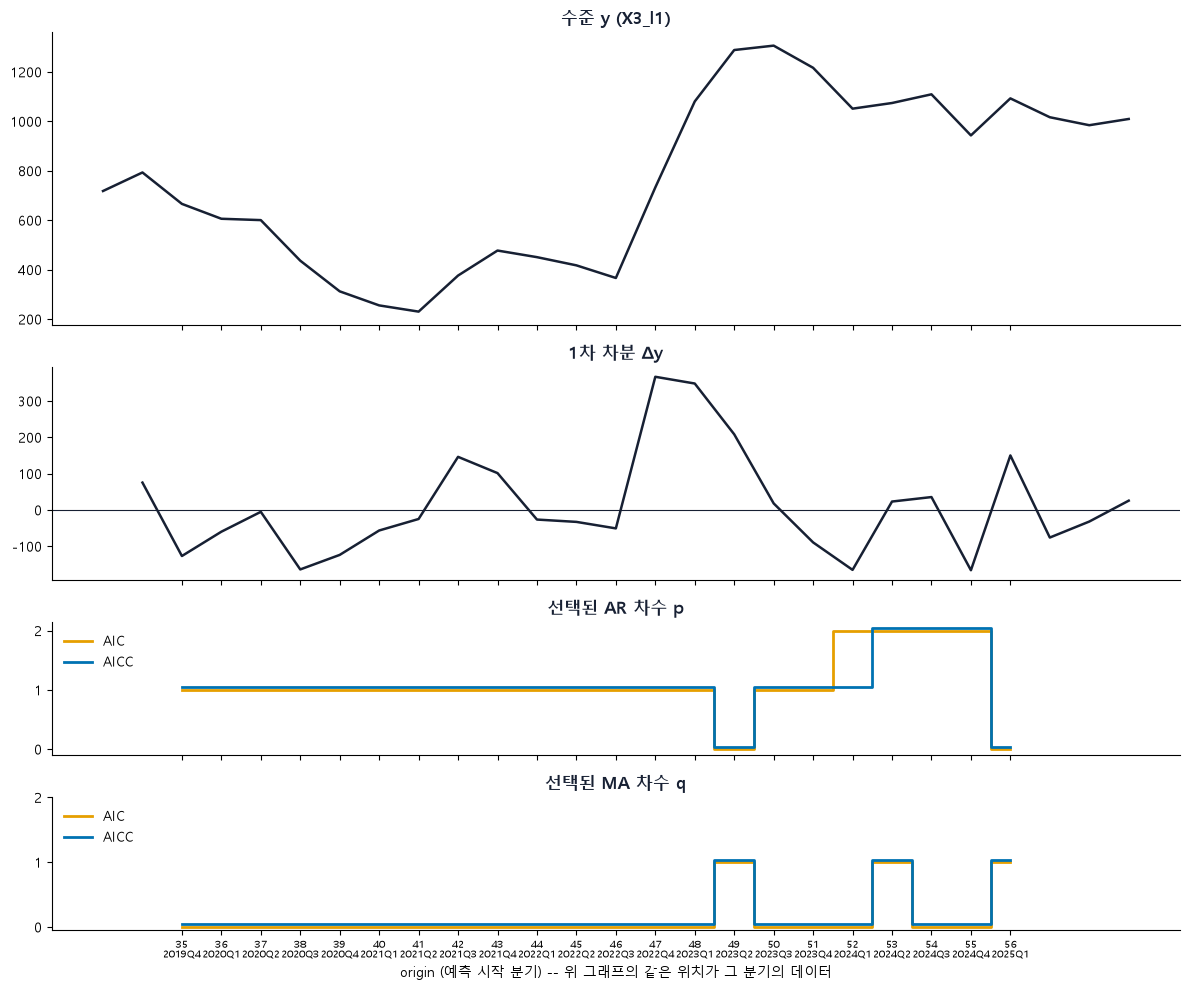

In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

print("선택된 (p,d,q)의 origin 수:")
display(res.groupby("ic")["order"].value_counts().unstack("ic").fillna(0).astype(int))

xl = [f"{o}\n{quarters[o]}" for o in scored_origins]
cols = {"aic": "#E69F00", "aicc": "#0072B2"}
t0 = scored_origins[0] - 2          # 첫 origin 직전 데이터부터 보여 준다
tt = np.arange(t0, len(vals))       # x축 = 분기 번호(origin n은 n번째 분기부터 예측)
dyv = np.diff(vals)

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.6, 1, 1]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=12, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=12, fontweight="bold", color="#172033")
for ax, key, t in [(axes[2], "p", "선택된 AR 차수 p"), (axes[3], "q", "선택된 MA 차수 q")]:
    for k, ic in enumerate(["aic", "aicc"]):
        ax.step(scored_origins, res.xs(ic, level="ic")[key].values + 0.04 * k, where="mid", color=cols[ic], linewidth=2, label=ic.upper())
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.set_yticks(range(0, 3))
    ax.legend(frameon=False, loc="upper left")
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


### 선택된 차수와 그때의 훈련 데이터 상태 (AICc)

위 그림에서 데이터(수준 y, 차분 Δy)와 선택된 p,q를 같은 위치에서 비교할 수 있다. 선택된 차수별 훈련 데이터의 상태를 표로 정리한다.

In [5]:
a = res.xs("aicc", level="ic")
rows = []
for o, row in a.iterrows():
    train = vals[:o]
    dtr = np.diff(train)
    rows.append({"origin": o, "order": row["order"], "훈련 n": len(train), "최근 8분기 Δy 표준편차": dtr[-8:].std(),
                 "전체 훈련 Δy 표준편차": dtr.std(), "훈련 Δy lag-1 자기상관": pd.Series(dtr).autocorr(1)})
state = pd.DataFrame(rows).set_index("origin")
display(state.groupby("order").agg(origin_수=("훈련 n", "size"), 훈련n_평균=("훈련 n", "mean"),
                                  최근8분기_Δy_표준편차=("최근 8분기 Δy 표준편차", "mean"),
                                  전체_Δy_표준편차=("전체 훈련 Δy 표준편차", "mean"),
                                  Δy_lag1_자기상관=("훈련 Δy lag-1 자기상관", "mean")).round(2))


,origin_수,훈련n_평균,최근8분기_Δy_표준편차,전체_Δy_표준편차,Δy_lag1_자기상관
order,,,,,
"(0, 1, 1)",2,52.50,163.99,99.93,0.50
"(1, 1, 0)",17,43.18,102.13,73.18,0.45
"(2, 1, 0)",2,54.50,185.42,100.47,0.52
"(2, 1, 1)",1,53.00,191.28,101.89,0.54


**그림과 표에서 보이는 것**

- **(1,1,0) 17개 origin**: 훈련 데이터가 비교적 조용하다(최근 8분기 Δy 표준편차 평균 102, lag-1 자기상관 0.45).
- **(1,1,0)이 아닌 5개 origin**: 모두 훈련에 2022~23년 급등(Δy +366, +347)이 들어간 뒤다. 최근 변동성이 164~191로 크고 lag-1 자기상관이 0.50~0.54로 약간 높다.
- 큰 변동이 들어와 최근 변동성이 커지면 AR 1차만으로 설명이 안 되어 차수가 바뀐다고 읽을 수 있다. 해당 origin이 5개뿐이라 서술적 관찰이다.

## 4. 성능 비교 -- AIC vs AICc


,커버리지,MSE,CRPS(7분위)
ic,,,
aic,61.364,1.177,0.627
aicc,61.364,1.164,0.621


22개 origin 중 AICc와 AIC의 성능이 같은 origin: 20개, 다른 origin: 2개 (차이 = AICc - AIC)


,AIC 모델,AICc 모델,MSE,CRPS(7분위)
origin,,,,
35,"(1, 1, 0) +절편","(1, 1, 0)",-0.284,-0.125
52,"(2, 1, 0)","(1, 1, 0)",-0.002,0.005


MSE 평균 차이(22개 평균): -0.013  CRPS(7분위) 평균 차이: -0.0055


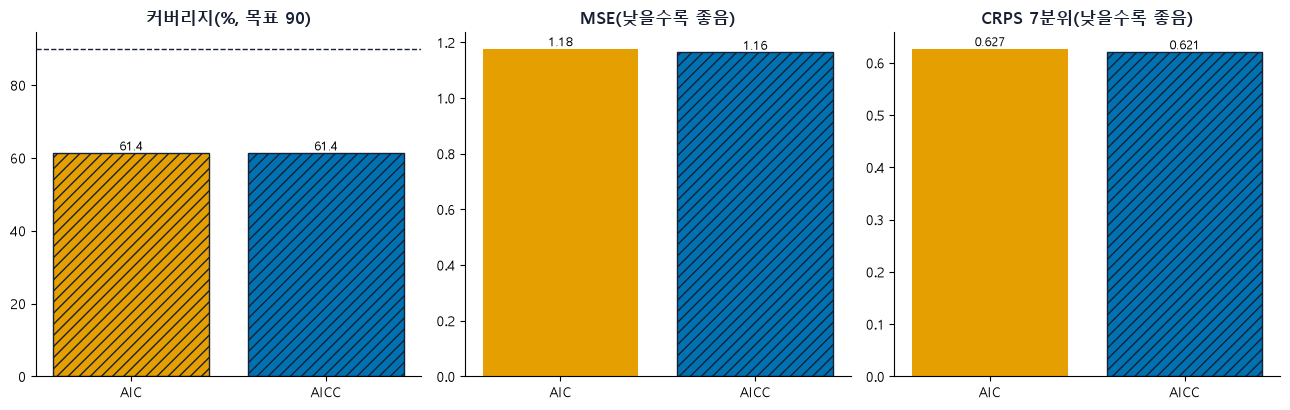

In [6]:
metrics = ["커버리지", "MSE", "CRPS(7분위)"]
summary = res.groupby("ic")[metrics].mean().round(3)
display(summary)

# 차이의 출처: 22개 origin 전체에서 (AICc - AIC)를 origin별로 본다 (평가가 아니라 어디서 차이가 생겼는지 확인)
gap = (res.xs("aicc", level="ic")[["MSE", "CRPS(7분위)"]] - res.xs("aic", level="ic")[["MSE", "CRPS(7분위)"]])
gap.insert(0, "AIC 모델", wide["aic"].astype(str) + np.where(icp["aic"], " +절편", ""))
gap.insert(1, "AICc 모델", wide["aicc"].astype(str) + np.where(icp["aicc"], " +절편", ""))
nz = gap[(gap["MSE"].abs() > 1e-9) | (gap["CRPS(7분위)"].abs() > 1e-9)]
print(f"22개 origin 중 AICc와 AIC의 성능이 같은 origin: {len(gap) - len(nz)}개, 다른 origin: {len(nz)}개 (차이 = AICc - AIC)")
display(nz.round(3))
print("MSE 평균 차이(22개 평균):", round(gap["MSE"].mean(), 4), " CRPS(7분위) 평균 차이:", round(gap["CRPS(7분위)"].mean(), 4))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (c, t) in zip(axes, [("커버리지", "커버리지(%, 목표 90)"), ("MSE", "MSE(낮을수록 좋음)"), ("CRPS(7분위)", "CRPS 7분위(낮을수록 좋음)")]):
    bars = ax.bar([i.upper() for i in summary.index], summary[c], color=[cols[i] for i in summary.index])
    if c != "구간폭":   # 폭은 좋고 나쁨이 없어 1등 표시를 하지 않는다
        score = (summary[c] - 90).abs() if c.startswith("커버리지") else summary[c]
        for b, k in zip(bars, summary.index):
            if score[k] <= score.min() + 1e-9:   # 1등(동률이면 모두)에 빗금
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.3g}", ha="center", va="bottom", fontsize=9)
    if c == "커버리지":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(t, fontsize=12, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


## 5. 결론

**AIC와 AICc는 이 데이터에서 거의 같은 모델을 고른다.**

- **차수**: 22개 중 21개에서 같은 (p,d,q)다. 다른 곳은 origin 52 하나(AIC (2,1,0), AICc (1,1,0))다. 표본이 35개 이상이라 AICc의 추가 벌점이 작다.
- **절편**: `with_intercept="auto"`는 d=1에서도 절편을 탐색하지만, 44개 모델 중 절편이 들어간 것은 origin 35의 AIC 모델 하나뿐이다.
- **안정성**: 22개 중 16~17개가 (1,1,0)이다. origin 35~48은 모두 (1,1,0), 훈련에 급등이 포함된 49~56부터 (0,1,1), (2,1,0), (2,1,1)로 바뀐다.

| 정보기준 | 커버리지(%) | MSE | CRPS(7분위) |
|---|---|---|---|
| AIC | 61.4 | 1.177 | 0.627 |
| AICc | 61.4 | 1.164 | 0.621 |

- **성능**: 22개 중 20개 origin은 성능이 정확히 같고, 평균 차이는 거의 전부 origin 35 한 곳(AIC가 절편 모델을 고름, MSE 차이 -0.284)에서 나온다. AICc가 일반적으로 우월하다는 근거로 보기 어렵다.

**결정**: 이후에는 AICc를 쓴다(소표본에 이론적으로 적절). 결과가 같아 AIC로 가도 결론은 같다.

**한계**: 차이가 origin 35 한 곳에 의존한다. 커버리지 61.4%로 목표 90%에 크게 못 미친다(구간이 좁음). 22개 origin이 겹쳐 유의성은 검증하지 않았다.

**다음 단계**: `9-3`에서 원 스케일의 리샘플링 구간과 자체 구간(7분위)을 비교한다.